In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('course_lead_scoring_2026.csv')

In [2]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.shape

(5000, 9)

In [4]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [6]:
for c in categorical:
    df[c] = df[c].fillna('NA')

In [7]:
for c in numerical:
    df[c] = df[c].fillna(0.0)

In [8]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [9]:
len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [10]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [11]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [12]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [13]:
df_train.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score'],
      dtype='str')

In [14]:
print('train:', df_train.shape, 'labels:', y_train.shape)
print('val:  ', df_val.shape,   'labels:', y_val.shape)
print('test: ', df_test.shape,  'labels:', y_test.shape)
print()
print('train 中 converted 的分布:')
print(pd.Series(y_train).value_counts(normalize=True))

train: (3000, 8) labels: (3000,)
val:   (1000, 8) labels: (1000,)
test:  (1000, 8) labels: (1000,)

train 中 converted 的分布:
1    0.576333
0    0.423667
Name: proportion, dtype: float64


In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [16]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [17]:
df_train.head(3)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
0,paid_ads,technology,employed,asia,80198.0,5,9,0.91
1,paid_ads,retail,employed,asia,50548.0,2,5,0.48
2,NA,finance,employed,NA,76300.0,0,3,0.42


In [20]:
from sklearn.metrics import roc_auc_score

for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    print(f'{col}: {auc:.3f}')
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(f'{col}: {auc:.3f}')

annual_income: 0.608
annual_income: 0.608
number_of_courses_viewed: 0.723
number_of_courses_viewed: 0.723
interaction_count: 0.765
interaction_count: 0.765
lead_score: 0.788
lead_score: 0.788


In [21]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [22]:
train_dict = df_train[categorical + numerical].to_dict(orient='records')

In [23]:
train_dict[:2]

[{'lead_source': 'paid_ads',
  'industry': 'technology',
  'employment_status': 'employed',
  'location': 'asia',
  'annual_income': 80198.0,
  'number_of_courses_viewed': 5,
  'interaction_count': 9,
  'lead_score': 0.91},
 {'lead_source': 'paid_ads',
  'industry': 'retail',
  'employment_status': 'employed',
  'location': 'asia',
  'annual_income': 50548.0,
  'number_of_courses_viewed': 2,
  'interaction_count': 5,
  'lead_score': 0.48}]

In [24]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dict)

In [25]:
X_train.shape

(3000, 28)

In [26]:
dv.get_feature_names_out()

array(['annual_income', 'employment_status=NA',
       'employment_status=employed', 'employment_status=self_employed',
       'employment_status=student', 'employment_status=unemployed',
       'industry=NA', 'industry=education', 'industry=finance',
       'industry=healthcare', 'industry=manufacturing', 'industry=retail',
       'industry=technology', 'interaction_count', 'lead_score',
       'lead_source=NA', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media', 'location=NA',
       'location=africa', 'location=asia', 'location=europe',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [27]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)


,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [32]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [33]:
X_val.shape

(1000, 28)

In [34]:
y_pred = model.predict_proba(X_val)[:, 1]

In [35]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_val, y_pred)
print(f'AUC: {auc:.4f}')

AUC: 0.7318


In [36]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [37]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]

In [38]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_val, y_pred)
print(f'AUC: {auc:.4f}')

AUC: 0.7318


In [39]:
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0.0, 1.0, 0.01)

scores = []

for t in thresholds:
    predicted = (y_pred >= t).astype(int)
    p = precision_score(y_val, predicted, zero_division=0)
    r = recall_score(y_val, predicted, zero_division=0)
    scores.append((t, p, r))

In [40]:
min_diff = float('inf')
intersection = None

for t, p, r in scores:
    if p == 0 and r == 0:
        continue
    diff = abs(p - r)
    if diff < min_diff:
        min_diff = diff
        intersection = t

print(f'交点阈值: {intersection:.2f}')
print(f'precision 和 recall 差值: {min_diff:.4f}')

交点阈值: 0.63
precision 和 recall 差值: 0.0075


In [41]:
import pandas as pd

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])
df_scores.head(20)

,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0
5,0.05,0.586,1.0
6,0.06,0.586,1.0
7,0.07,0.586,1.0
8,0.08,0.586,1.0
9,0.09,0.586,1.0


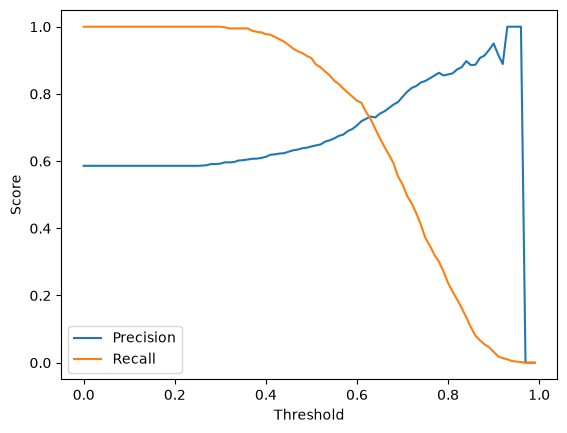

In [43]:
import matplotlib.pyplot as plt

plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.show()

In [44]:
from sklearn.metrics import f1_score

In [45]:
thresholds = np.arange(0.0, 1.0, 0.01)

f1_scores = []

for t in thresholds:
    predicted = (y_pred >= t).astype(int)
    f1 = f1_score(y_val, predicted, zero_division=0)
    f1_scores.append(f1)

In [46]:
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f'最大 F1: {best_f1:.4f}')
print(f'对应阈值: {best_threshold:.2f}')

最大 F1: 0.7576
对应阈值: 0.41


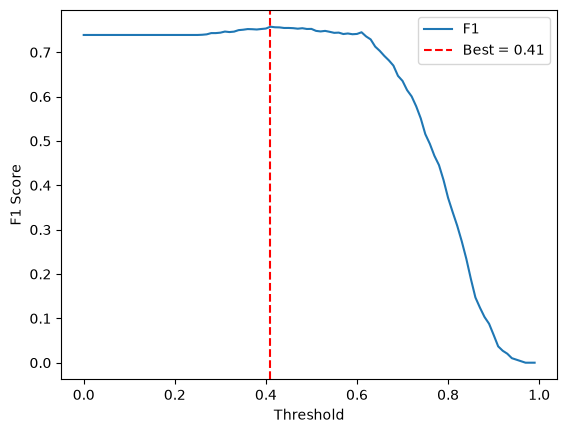

In [47]:
import matplotlib.pyplot as plt

plt.plot(thresholds, f1_scores, label='F1')
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best = {best_threshold:.2f}')
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.legend()
plt.show()

In [48]:
df_full_train.shape


(4000, 9)

In [49]:
from sklearn.model_selection import KFold

In [50]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    # 切片得到每一折的训练集和验证集
    df_tr = df_full_train.iloc[train_idx]
    df_vl = df_full_train.iloc[val_idx]
    
    # 分离特征和标签
    y_tr = df_tr.converted.values
    y_vl = df_vl.converted.values
    
    # 转成字典
    tr_dict = df_tr[categorical + numerical].to_dict(orient='records')
    vl_dict = df_vl[categorical + numerical].to_dict(orient='records')
    
    # 独热编码
    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(tr_dict)
    X_vl = dv.transform(vl_dict)
    
    # 训练
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_tr, y_tr)
    
    # 预测 + 算 AUC
    y_pred_cv = model.predict_proba(X_vl)[:, 1]
    auc = roc_auc_score(y_vl, y_pred_cv)
    scores.append(auc)

In [51]:
print('5 折 AUC 分数:', scores)
print(f'平均 AUC: {np.mean(scores):.4f}')
print(f'标准差:   {np.std(scores):.4f}')

5 折 AUC 分数: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
平均 AUC: 0.7317
标准差:   0.0069


In [52]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    
    scores = []
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_vl = df_full_train.iloc[val_idx]
        
        y_tr = df_tr.converted.values
        y_vl = df_vl.converted.values
        
        tr_dict = df_tr[categorical + numerical].to_dict(orient='records')
        vl_dict = df_vl[categorical + numerical].to_dict(orient='records')
        
        dv = DictVectorizer(sparse=False)
        X_tr = dv.fit_transform(tr_dict)
        X_vl = dv.transform(vl_dict)
        
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_tr, y_tr)
        
        y_pred_cv = model.predict_proba(X_vl)[:, 1]
        auc = roc_auc_score(y_vl, y_pred_cv)
        scores.append(auc)
    
    mean = np.mean(scores)
    std = np.std(scores)
    print(f'C={C:.6f}  mean={mean:.3f}  std={std:.3f}')

C=0.000001  mean=0.617  std=0.019
C=0.001000  mean=0.749  std=0.010
C=1.000000  mean=0.732  std=0.007
